# BÀI 2: xây dựng quy trình dự đoán giá nhà

Họ tên: Đặng Văn Chung

Mã sinh viên: 24174800194

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

uploaded = files.upload()

Saving kc_house_data.csv to kc_house_data.csv


Tải tệp dữ liệu

In [ ]:
house_df = pd.read_csv("kc_house_data.csv")

print("Kích thước dữ liệu:", house_df.shape)

print("\n5 dòng đầu:")
display(house_df.head())

print("\nKiểu dữ liệu:")
print(house_df.dtypes)

print("\nSố giá trị thiếu:")
print(house_df.isnull().sum())

print("\nSố dòng trùng lặp:")
print(house_df.duplicated().sum())

print("\nThống kê giá nhà:")
display(house_df["price"].describe())

Kích thước dữ liệu: (21613, 21)

5 dòng đầu:


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503



Kiểu dữ liệu:
id                 int64
date              object
price            float64
bedrooms           int64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
grade              int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
zipcode            int64
lat              float64
long             float64
sqft_living15      int64
sqft_lot15         int64
dtype: object

Số giá trị thiếu:
id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64

Số dòng trùng 

,price
count,2.161300e+04
mean,5.400881e+05
std,3.671272e+05
min,7.500000e+04
25%,3.219500e+05
50%,4.500000e+05
75%,6.450000e+05
max,7.700000e+06


Kiểm tra dữ liệu

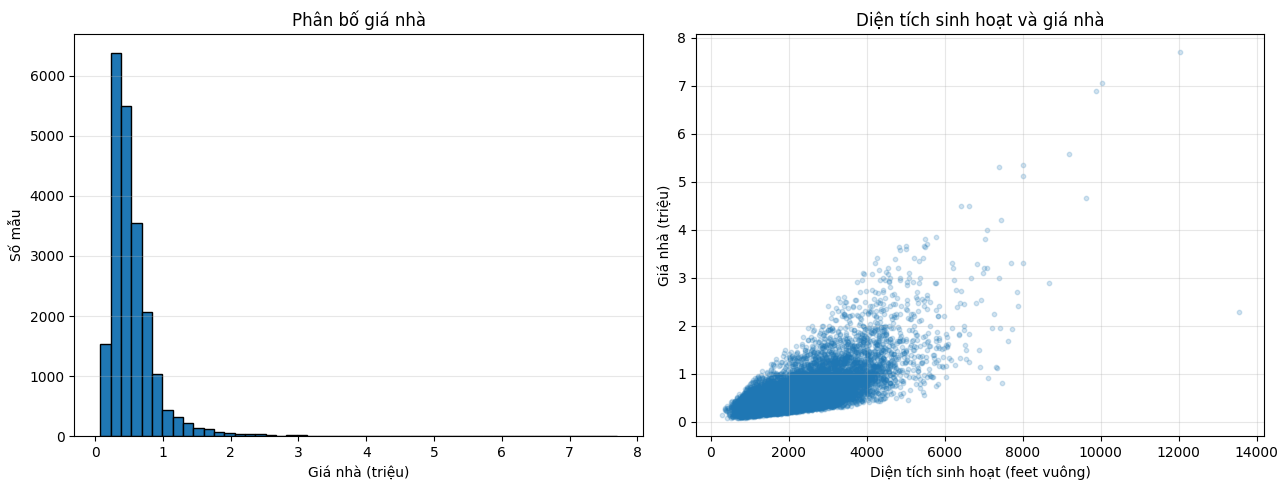

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Phân bố giá nhà
axes[0].hist(
    house_df["price"] / 1_000_000,
    bins=50,
    edgecolor="black"
)
axes[0].set_title("Phân bố giá nhà")
axes[0].set_xlabel("Giá nhà (triệu)")
axes[0].set_ylabel("Số mẫu")
axes[0].grid(axis="y", alpha=0.3)

# Diện tích sinh hoạt và giá nhà
axes[1].scatter(
    house_df["sqft_living"],
    house_df["price"] / 1_000_000,
    alpha=0.2,
    s=10
)
axes[1].set_title("Diện tích sinh hoạt và giá nhà")
axes[1].set_xlabel("Diện tích sinh hoạt (feet vuông)")
axes[1].set_ylabel("Giá nhà (triệu)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Kiểm tra ngoại lệ bằng IQR

In [ ]:
house_check_cols = [
    "price",
    "sqft_living",
    "sqft_lot",
    "bedrooms",
    "bathrooms"
]

house_outlier_summary = []

for col in house_check_cols:
    q1 = house_df[col].quantile(0.25)
    q3 = house_df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    mask = (
        (house_df[col] < lower) |
        (house_df[col] > upper)
    )

    house_outlier_summary.append({
        "Đặc trưng": col,
        "Ngưỡng dưới": lower,
        "Ngưỡng trên": upper,
        "Số ngoại lệ": int(mask.sum()),
        "Tỷ lệ (%)": mask.mean() * 100
    })

house_outlier_df = pd.DataFrame(house_outlier_summary)

display(house_outlier_df.round(2))

,Đặc trưng,Ngưỡng dưới,Ngưỡng trên,Số ngoại lệ,Tỷ lệ (%)
0,price,-162625.00,1129575.00,1146,5.30
1,sqft_living,-257.50,4234.50,572,2.65
2,sqft_lot,-3432.00,19160.00,2425,11.22
3,bedrooms,1.50,5.50,546,2.53
4,bathrooms,0.62,3.62,571,2.64


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

# Thông tin đầu vào và giá nhà cần dự đoán
X_house = house_df.drop(columns=["price", "id"]).copy()
y_house = house_df["price"].copy()

# Chia khoảng 80% số căn nhà để học, 20% để kiểm tra
house_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    house_splitter.split(
        X_house,
        y_house,
        groups=house_df["id"]
    )
)

X_house_train = X_house.iloc[train_idx].copy()
X_house_test = X_house.iloc[test_idx].copy()

y_house_train = y_house.iloc[train_idx].copy()
y_house_test = y_house.iloc[test_idx].copy()

# Kiểm tra kết quả chia
train_ids = set(house_df.iloc[train_idx]["id"])
test_ids = set(house_df.iloc[test_idx]["id"])

print("Train:", X_house_train.shape)
print("Test:", X_house_test.shape)
print("Số id chung giữa hai tập:", len(train_ids & test_ids))

Train: (17289, 19)
Test: (4324, 19)
Số id chung giữa hai tập: 0


In [ ]:
def prepare_house_features(data, engineer=False):
    result = data.copy()

    # Mã khu vực được xem là một nhóm, không phải số đo
    result["zipcode"] = result["zipcode"].astype(str)

    if engineer:
        sale_date = pd.to_datetime(
            result["date"],
            format="%Y%m%dT%H%M%S"
        )

        result["sale_year"] = sale_date.dt.year
        result["sale_month"] = sale_date.dt.month

        result["house_age"] = (
            result["sale_year"] - result["yr_built"]
        ).clip(lower=0)

        result["is_renovated"] = (
            result["yr_renovated"] > 0
        ).astype(int)

        result["has_basement"] = (
            result["sqft_basement"] > 0
        ).astype(int)

        result["log_sqft_living"] = np.log1p(
            result["sqft_living"]
        )

        result["log_sqft_lot"] = np.log1p(
            result["sqft_lot"]
        )

        result["living_grade"] = (
            result["sqft_living"] * result["grade"]
        )

    return result.drop(columns=["date"])


# Xem thử kết quả trên tập Train
house_base_preview = prepare_house_features(
    X_house_train,
    engineer=False
)

house_fe_preview = prepare_house_features(
    X_house_train,
    engineer=True
)

new_house_cols = [
    col for col in house_fe_preview.columns
    if col not in house_base_preview.columns
]

print("Đặc trưng gốc:", house_base_preview.shape)
print("Sau Feature Engineering:", house_fe_preview.shape)

display(house_fe_preview[new_house_cols].head().round(3))

Đặc trưng gốc: (17289, 18)
Sau Feature Engineering: (17289, 26)


,sale_year,sale_month,house_age,is_renovated,has_basement,log_sqft_living,log_sqft_lot,living_grade
0,2014,10,59,0,0,7.074,8.640,8260
1,2014,12,63,1,1,7.852,8.888,17990
2,2015,2,82,0,0,6.648,9.210,4620
3,2014,12,49,0,1,7.581,8.517,13720
5,2014,5,13,0,1,8.598,11.532,59620


Xây dựng Pipeline và Feature Selection

In [ ]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    FunctionTransformer
)
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import LinearRegression, Ridge


def build_house_pipeline(model, engineer=False, select=False):
    # Xử lý các cột số
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    # Xử lý cột phân loại như zipcode
    category_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            drop="first",
            sparse_output=False
        ))
    ])

    # Áp dụng cách xử lý phù hợp cho từng nhóm cột
    preprocess = ColumnTransformer([
        (
            "numeric",
            numeric_pipeline,
            make_column_selector(dtype_include=np.number)
        ),
        (
            "category",
            category_pipeline,
            make_column_selector(dtype_include=object)
        )
    ])

    # Bật hoặc tắt việc chọn lọc đặc trưng
    if select:
        selection = SelectKBest(
            score_func=f_regression,
            k=30
        )
    else:
        selection = "passthrough"

    # Ghép thành Pipeline hoàn chỉnh
    return Pipeline([
        ("features", FunctionTransformer(
            prepare_house_features,
            kw_args={"engineer": engineer},
            validate=False
        )),
        ("preprocess", preprocess),
        ("selection", selection),
        ("model", clone(model))
    ])


house_example_pipeline = build_house_pipeline(
    LinearRegression(),
    engineer=True,
    select=True
)

print("Các bước trong Pipeline:")
for name, step in house_example_pipeline.steps:
    print(name)

Các bước trong Pipeline:
features
preprocess
selection
model


In [ ]:
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

house_models = {
    "Linear Regression": LinearRegression(),

    "Ridge": Ridge(alpha=1.0),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

# Mỗi cặp giá trị là: (engineer, select)
house_cases = {
    "Gốc": (False, False),
    "Engineering": (True, False),
    "Selection": (False, True),
    "Engineering + Selection": (True, True)
}

print("Tổng số lần huấn luyện:",
      len(house_models) * len(house_cases))

Tổng số lần huấn luyện: 16


In [ ]:
house_results = []
house_fitted_pipelines = {}

for case_name, (engineer, select) in house_cases.items():
    for model_name, model in house_models.items():

        print("Đang chạy:", case_name, "-", model_name,
              flush=True)

        pipe = build_house_pipeline(
            model,
            engineer=engineer,
            select=select
        )

        # Học từ tập Train
        pipe.fit(X_house_train, y_house_train)

        # Dự đoán
        train_pred = pipe.predict(X_house_train)
        test_pred = pipe.predict(X_house_test)

        # Số đặc trưng thực tế đưa vào mô hình
        n_features = pipe[:-1].transform(
            X_house_train.iloc[:1]
        ).shape[1]

        # Ghi kết quả đánh giá
        house_results.append({
            "Trường hợp": case_name,
            "Mô hình": model_name,
            "Số đặc trưng": n_features,
            "MAE": mean_absolute_error(
                y_house_test, test_pred
            ),
            "RMSE": np.sqrt(mean_squared_error(
                y_house_test, test_pred
            )),
            "R2 Test": r2_score(
                y_house_test, test_pred
            ),
            "R2 Train": r2_score(
                y_house_train, train_pred
            )
        })

        # Giữ lại Pipeline đã học để dùng ở bước sau
        house_fitted_pipelines[
            (case_name, model_name)
        ] = pipe

comparison_bai4 = (
    pd.DataFrame(house_results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(comparison_bai4.round({
    "MAE": 2,
    "RMSE": 2,
    "R2 Test": 4,
    "R2 Train": 4
}))

Đang chạy: Gốc - Linear Regression
Đang chạy: Gốc - Ridge
Đang chạy: Gốc - Random Forest
Đang chạy: Gốc - Gradient Boosting
Đang chạy: Engineering - Linear Regression
Đang chạy: Engineering - Ridge
Đang chạy: Engineering - Random Forest
Đang chạy: Engineering - Gradient Boosting
Đang chạy: Selection - Linear Regression
Đang chạy: Selection - Ridge
Đang chạy: Selection - Random Forest
Đang chạy: Selection - Gradient Boosting
Đang chạy: Engineering + Selection - Linear Regression
Đang chạy: Engineering + Selection - Ridge
Đang chạy: Engineering + Selection - Random Forest
Đang chạy: Engineering + Selection - Gradient Boosting


,Trường hợp,Mô hình,Số đặc trưng,MAE,RMSE,R2 Test,R2 Train
0,Gốc,Random Forest,86,68572.21,121226.82,0.8948,0.9717
1,Engineering,Random Forest,94,68335.65,121924.25,0.8936,0.9733
2,Gốc,Gradient Boosting,86,75516.99,125944.64,0.8864,0.9053
3,Engineering,Gradient Boosting,94,76267.47,129597.48,0.8797,0.9088
4,Engineering + Selection,Gradient Boosting,30,82040.66,135953.39,0.8677,0.8877
5,Selection,Random Forest,30,77356.47,136191.12,0.8672,0.9630
6,Selection,Gradient Boosting,30,81843.26,136691.80,0.8662,0.8894
7,Engineering + Selection,Random Forest,30,78825.52,138591.17,0.8625,0.9626
8,Engineering,Linear Regression,94,86018.45,142669.47,0.8543,0.8440
9,Engineering,Ridge,94,85908.53,142839.57,0.8539,0.8432


Trực quan hóa kết quả so sánh

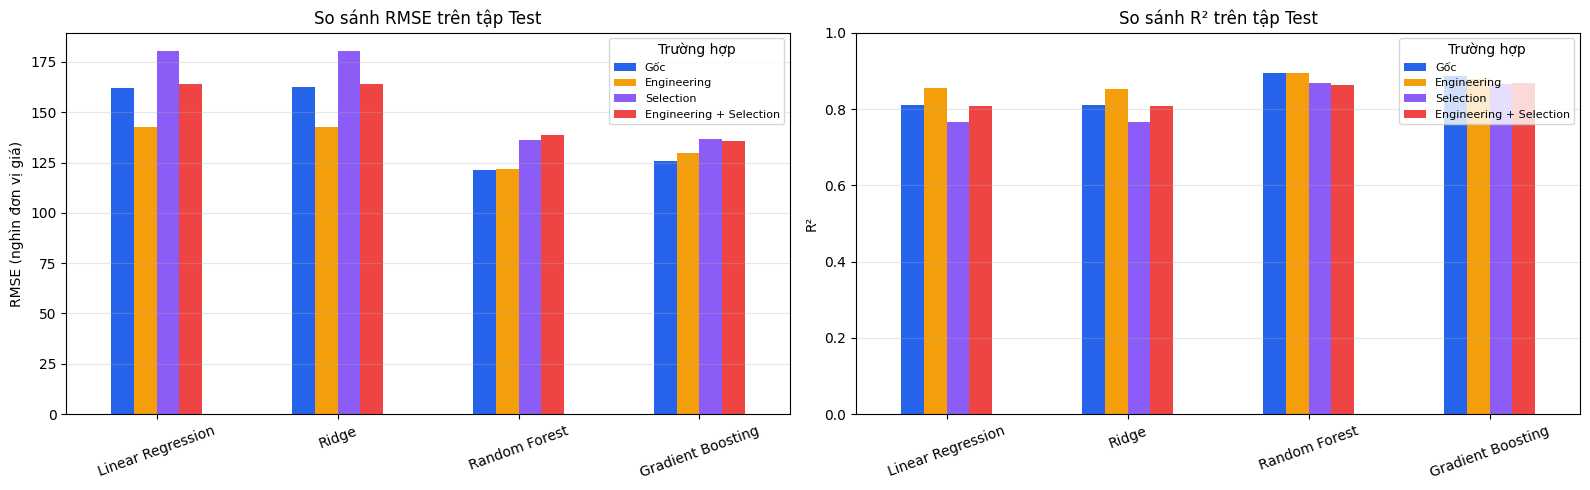

In [ ]:
case_order = list(house_cases.keys())
model_order = list(house_models.keys())

rmse_table = comparison_bai4.pivot(
    index="Mô hình",
    columns="Trường hợp",
    values="RMSE"
).reindex(index=model_order, columns=case_order)

r2_table = comparison_bai4.pivot(
    index="Mô hình",
    columns="Trường hợp",
    values="R2 Test"
).reindex(index=model_order, columns=case_order)

colors = ["#2563eb", "#f59e0b", "#8b5cf6", "#ef4444"]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

(rmse_table / 1000).plot(
    kind="bar",
    ax=axes[0],
    color=colors,
    rot=20
)
axes[0].set_title("So sánh RMSE trên tập Test")
axes[0].set_ylabel("RMSE (nghìn đơn vị giá)")
axes[0].set_xlabel("")
axes[0].grid(axis="y", alpha=0.3)
axes[0].legend(title="Trường hợp", fontsize=8)

r2_table.plot(
    kind="bar",
    ax=axes[1],
    color=colors,
    rot=20
)
axes[1].set_title("So sánh R² trên tập Test")
axes[1].set_ylabel("R²")
axes[1].set_xlabel("")
axes[1].set_ylim(0, 1)
axes[1].grid(axis="y", alpha=0.3)
axes[1].legend(title="Trường hợp", fontsize=8)

plt.tight_layout()
plt.show()

Kiểm tra dự đoán và phần dư.

Cấu hình: ('Gốc', 'Random Forest')
MAE: 68572.21
RMSE: 121226.82
R2 Test: 0.8948


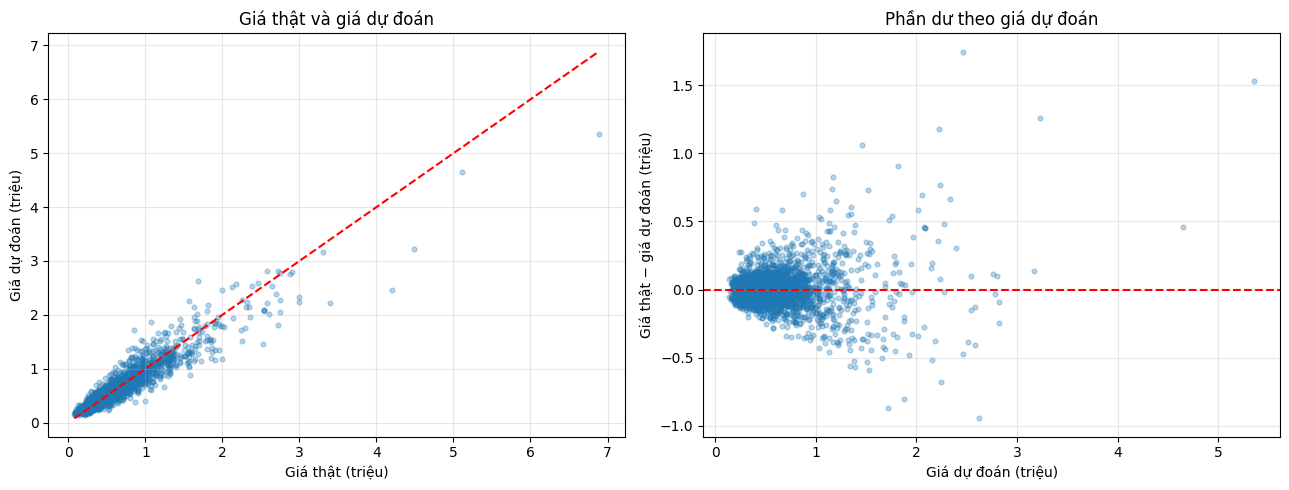

In [ ]:
# Lấy cấu hình có RMSE thấp nhất
best_house_row = comparison_bai4.loc[
    comparison_bai4["RMSE"].idxmin()
]

best_house_key = (
    best_house_row["Trường hợp"],
    best_house_row["Mô hình"]
)

# Dùng lại Pipeline đã huấn luyện
best_house_pipeline = house_fitted_pipelines[best_house_key]

house_best_pred = best_house_pipeline.predict(X_house_test)
house_actual = y_house_test.to_numpy()

# Phần dư = giá thật - giá dự đoán
house_residuals = house_actual - house_best_pred

print("Cấu hình:", best_house_key)
print("MAE:", round(best_house_row["MAE"], 2))
print("RMSE:", round(best_house_row["RMSE"], 2))
print("R2 Test:", round(best_house_row["R2 Test"], 4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Giá thật và giá dự đoán
axes[0].scatter(
    house_actual / 1_000_000,
    house_best_pred / 1_000_000,
    alpha=0.3,
    s=12
)

low = min(house_actual.min(), house_best_pred.min()) / 1_000_000
high = max(house_actual.max(), house_best_pred.max()) / 1_000_000

axes[0].plot([low, high], [low, high], "r--")
axes[0].set_title("Giá thật và giá dự đoán")
axes[0].set_xlabel("Giá thật (triệu)")
axes[0].set_ylabel("Giá dự đoán (triệu)")
axes[0].grid(alpha=0.3)

# Phần dư theo giá dự đoán
axes[1].scatter(
    house_best_pred / 1_000_000,
    house_residuals / 1_000_000,
    alpha=0.3,
    s=12
)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Phần dư theo giá dự đoán")
axes[1].set_xlabel("Giá dự đoán (triệu)")
axes[1].set_ylabel("Giá thật − giá dự đoán (triệu)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Nhận xét và kết luận bài 4

Bài thực hành xây dựng Pipeline dự đoán giá nhà trên bộ dữ liệu `kc_house_data`. Dữ liệu được chia theo `id`, giúp các giao dịch của cùng một căn nhà chỉ nằm trong tập Train hoặc Test. Các bước chuẩn hóa, mã hóa và chọn lọc đặc trưng được học từ tập Train.

Bốn mô hình Linear Regression, Ridge, Random Forest và Gradient Boosting được thử với bốn trường hợp: đặc trưng gốc, Feature Engineering, Feature Selection, và kết hợp Engineering với Selection. Tổng cộng có 16 kết quả để so sánh.

**So sánh mô hình:** Random Forest với bộ đặc trưng gốc đạt RMSE thấp nhất là 121226.82 và R² Test cao nhất là 0.8948. MAE đạt 68572.21, nghĩa là sai lệch tuyệt đối trung bình khoảng 68.57 nghìn đơn vị giá. R² này thể hiện mức giải thích biến thiên của giá nhà, không phải tỷ lệ dự đoán đúng.

**Tác dụng của Feature Engineering:** Các đặc trưng mới giúp Linear Regression và Ridge cải thiện rõ. Tuy nhiên, RMSE của Random Forest và Gradient Boosting chưa được cải thiện. Random Forest kết hợp Engineering đạt MAE thấp nhất là 68335.65, nhưng RMSE cao hơn bộ gốc một chút.

**Tác dụng của Feature Selection:** Việc chọn 30 đặc trưng làm giảm số cột đầu vào nhưng chưa cải thiện hiệu năng so với bộ gốc trong các cấu hình đã thử. Vì vậy, ít đặc trưng hơn không đồng nghĩa với dự đoán tốt hơn.

**Dự đoán và phần dư:** Nhiều điểm nằm gần đường giá dự đoán bằng giá thật. Tuy nhiên, một số căn nhà giá cao bị dự đoán thấp hơn thực tế. Phần dư phân tán rộng hơn ở vùng giá cao, cho thấy mức sai số chưa đồng đều giữa các nhóm giá. Random Forest có R² Train = 0.9717 cao hơn R² Test = 0.8948, nên vẫn cần lưu ý khả năng học quá khớp.

**Kết luận:** Nếu ưu tiên RMSE, Random Forest với bộ đặc trưng gốc cho kết quả tốt nhất trong lần thử này. Hiệu quả của Engineering và Selection phụ thuộc vào mô hình; cần đánh giá bằng nhiều chỉ số. Kết luận hiện tại áp dụng cho cách chia dữ liệu và các tham số đã sử dụng.